Dataset Preview:
       price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Dataset Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 

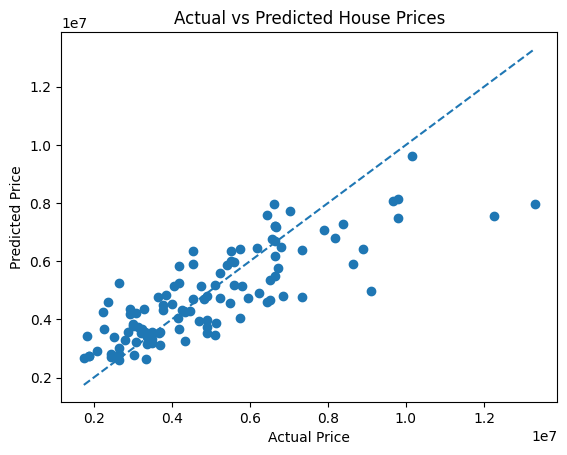

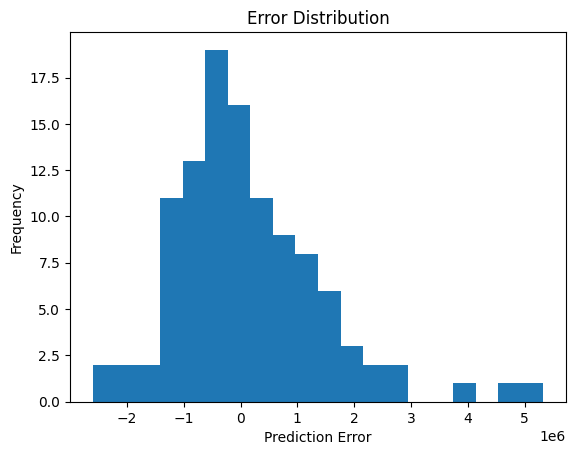


NOTE: Prediction input is skipped due to encoded features complexity.


In [ ]:
# -----------------------------
# HOUSE PRICE PREDICTION PROJECT
# -----------------------------

# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Load Dataset
df = pd.read_csv("/content/Housing (1).csv")

print("Dataset Preview:\n", df.head())
print("\nDataset Info:\n")
print(df.info())

# -----------------------------
# Step 3: Data Preprocessing
# -----------------------------

# Check missing values
print("\nMissing Values:\n", df.isnull().sum())

# Fill missing values
df = df.fillna(df.mean(numeric_only=True))

# Handle categorical data (yes/no, etc.)
categorical_cols = df.select_dtypes(include='object').columns
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# -----------------------------
# Step 4: Feature Selection
# -----------------------------
X = df.drop('price', axis=1).values
y = df['price'].values

# -----------------------------
# Step 5: Train-Test Split
# -----------------------------
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -----------------------------
# Step 6: Train Model
# -----------------------------
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# -----------------------------
# Step 7: Prediction
# -----------------------------
y_pred = model.predict(X_test)

# -----------------------------
# Step 8: Model Evaluation
# -----------------------------
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n📊 Model Performance:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score (Accuracy):", r2)
#y= mx+c

# -----------------------------
# Step 9: Coefficients
# -----------------------------
print("\nModel Coefficients:\n", model.coef_)
print("Intercept:", model.intercept_)

# -----------------------------
# Step 10: GRAPH 1
# Actual vs Predicted
# -----------------------------
plt.figure()

plt.scatter(y_test, y_pred)

# Ideal line (perfect prediction)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         linestyle='--')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

# -----------------------------
# Step 11: GRAPH 2
# Error Distribution
# -----------------------------
errors = y_test - y_pred

plt.figure()
plt.hist(errors, bins=20)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Error Distribution")

plt.show()

# -----------------------------
# Step 12: Prediction (Optional)
# -----------------------------
print("\nNOTE: Prediction input is skipped due to encoded features complexity.")

# If you want prediction, you must match encoded columns exactly.